# P7. 데이터 품질 리포트 자동화

서울 부동산 실거래 넉 달치(2026년 6~9월)를 한 달씩 묶음으로 넣으며, 표로 적어 둔 품질 규칙 21개를 DuckDB SQL 로 돌려 결과를 쌓고 일별 품질 리포트(Markdown · HTML · 그래프)를 자동으로 냅니다. 일부러 깨뜨린 묶음(열 빠짐 · 단위 바뀜 · 늦게 온 묶음)을 규칙이 잡는지 보고, 마지막에 Airflow DAG 로 매일 돌리는 모양까지 만듭니다.

- 단계: 개별 프로젝트 · 정형 · 예상 2~3일
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: 서울 열린데이터광장 — 서울시 부동산 실거래가 정보(OA-21275) 계약일 2026년 6~9월분(2026-10-28 내려받음), 공공누리 1유형(출처표시)

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/P7/P7_blank.ipynb)으로 다시 쳐 보세요.

데이터 파이프라인이 멈추는 일보다 더 무서운 것은 **멈추지 않고 틀린 데이터를 흘려보내는 일**입니다.
어느 날 원천 기관이 금액 단위를 만원에서 원으로 바꾸면, 적재도 집계도 대시보드도 오류 없이 돌아가고 평당가만 만 배가 됩니다. 아무도 모른 채로요.

이 프로젝트에서는 P1 에서 쓴 서울 부동산 실거래 자료에 **품질 규칙**을 붙입니다. 규칙은 코드 여기저기에 `if` 로 흩어 두지 않고 **표(데이터)** 로 관리합니다.
규칙 한 줄이 SQL 한 문장이 되고, 결과는 다시 표로 쌓이고, 그 표에서 리포트가 나옵니다. 외부 품질 도구 없이 pandas 와 DuckDB 만 씁니다.

```text
landing/<도착일>/trade.csv ─ 규칙 표(dq_rules) ─ 실행기(DuckDB SQL) ─ 결과 표(dq_results · dq_runs)
                                                                    ├─ 리포트 reports/dq_<날짜>.md · .html · .png
                                                                    └─ 통과한 묶음만 trade_clean 에 적재
Airflow DAG(@daily) 가 매일 위 과정을 한 번 부릅니다.
```

다 끝내면 다음을 말할 수 있습니다.

- 실거래 자료에 어떤 품질 규칙이 필요하고, 왜 그 기준값(범위 · 허용 비율)을 골랐는지
- 처음 돌린 규칙이 「경고」를 낼 때, 데이터가 틀린 것인지 규칙이 틀린 것인지 가리는 방법
- 열이 빠진 묶음 · 금액 단위가 바뀐 묶음 · 면적 단위가 바뀐 묶음 · 늦게 온 묶음을 각각 어떤 규칙이 잡는지

## 1단계 · 준비 — 라이브러리와 데이터

pandas · DuckDB · matplotlib 만 씁니다. Colab 에 모두 들어 있습니다.

데이터는 서울 열린데이터광장 「서울시 부동산 실거래가 정보」(OA-21275)에서 계약일이 2026년 6~9월인 거래를 내려받아 둔 스냅샷입니다(2026-10-28 기준, 35,610건, P1 과 같은 파일).
국토교통부 실거래가 공개시스템을 연계한 자료이고, 이용허락은 **공공누리 1유형(출처표시)** 이라 다시 나눠 줄 수 있습니다. 글자 인코딩은 원본 그대로 CP949 입니다.

In [ ]:
import os, json, shutil, urllib.request
import pandas as pd
import duckdb

DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

path = fetch("seoul_realestate_trade_202606_09.csv.gz")
print(path, round(os.path.getsize(path) / 1e6, 1), "MB")
print("duckdb", duckdb.__version__, "· pandas", pd.__version__)

data/seoul_realestate_trade_202606_09.csv.gz 1.0 MB
duckdb 1.3.2 · pandas 2.3.3


> **확인 포인트** — `data/seoul_realestate_trade_202606_09.csv.gz 1.0 MB` 가 찍힙니다.

## 2단계 · 묶음 만들기 — 한 달치씩 도착한다고 보기

실제 운영에서는 원천 파일이 매일 한 번씩 「착륙장(landing)」 폴더에 떨어지고, 품질 검사는 그 파일을 받아서 시작합니다.
여기서는 넉 달치 스냅샷을 **계약월 하나 = 묶음 하나**로 나누고, 각 묶음이 다음 달 1일에 도착한 것으로 둡니다(연습용 일정 — 실제 도착 날짜가 아닙니다).

먼저 일부러 아무 설정 없이 읽어 봅니다. 공공기관 CSV 라 인코딩부터 막힙니다.

In [ ]:
try:
    pd.read_csv(path, nrows=5)
except UnicodeDecodeError as e:
    print("읽기 실패:", str(e)[:70])

읽기 실패: 'utf-8' codec can't decode byte 0xc1 in position 1: invalid start byte


인코딩만 알려 주면 읽히기는 합니다. 그런데 pandas 가 형을 짐작하게 두면 품질 검사 전에 이미 데이터가 바뀝니다.

In [ ]:
guess = pd.read_csv(path, encoding="cp949", nrows=3)
print(guess[["자치구코드", "본번", "부번"]])
print(guess[["자치구코드", "본번"]].dtypes.to_dict())

   자치구코드    본번  부번
0  11530   296   0
1  11290  1021   0
2  11110   105   2
{'자치구코드': dtype('int64'), '본번': dtype('int64')}


번지 `0296` 이 숫자 `296` 이 되었습니다. 품질 검사는 **받은 그대로**를 봐야 하므로 모든 열을 글자로 읽고, 형 검사는 규칙이 합니다.

In [ ]:
raw = pd.read_csv(path, encoding="cp949", dtype=str)
print(raw.shape)

ARRIVE = {"202606": "2026-07-01", "202607": "2026-08-01", "202608": "2026-09-01", "202609": "2026-10-01"}
for ym, day in ARRIVE.items():
    part = raw[raw["계약일"].str[:6] == ym]
    os.makedirs(f"landing/{day}", exist_ok=True)
    part.to_csv(f"landing/{day}/trade.csv", index=False)
    print(day, "도착 ←", ym, len(part), "행")

(35610, 21)
2026-07-01 도착 ← 202606 10348 행


2026-08-01 도착 ← 202607 10531 행
2026-09-01 도착 ← 202608 7488 행


2026-10-01 도착 ← 202609 7243 행


> **확인 포인트** — 전체 `(35610, 21)`, 묶음은 2026-07-01 10,348행 · 08-01 10,531행 · 09-01 7,488행 · 10-01 7,243행입니다.
> 8 · 9월이 적은 것은 신고 기한(계약 뒤 30일)이 남아 아직 덜 들어온 탓도 있습니다(P1 3단계).

In [ ]:
assert raw.shape == (35610, 21)
sizes = [len(pd.read_csv(f"landing/{d}/trade.csv", dtype=str)) for d in ARRIVE.values()]
assert sizes == [10348, 10531, 7488, 7243]

착륙장 파일은 UTF-8 로 저장했습니다. 원천의 인코딩 문제는 받는 순간 한 번만 풀고, 그 뒤 단계는 신경 쓰지 않게 하는 것이 보통입니다.

## 3단계 · 규칙을 표로 — dq_rules

규칙 하나는 표의 한 줄입니다. 열은 이렇게 정합니다.

| 열 | 뜻 | 예 |
|---|---|---|
| `rule_id` | 규칙 번호(기본 키) | `R08` |
| `kind` | 검사 종류 — 실행기가 SQL 로 바꿀 줄 아는 이름 | `range` |
| `col` | 검사할 열 | `물건금액(만원)` |
| `params` | 종류마다 필요한 값(JSON) | `{"min": 500, "max": 3000000}` |
| `where_sql` | 이 조건에 맞는 행만 검사(없으면 전체) | `건물용도 <> '단독다가구'` |
| `severity` | `error`(적재를 막음) · `warn`(알리기만) | `error` |
| `max_fail_rate` | 어겨도 되는 비율의 상한 | `0` |

이렇게 두면 규칙을 고칠 때 코드를 고치지 않고 **표의 값**만 바꿉니다. 누가 언제 어떤 기준을 바꿨는지도 표의 변경으로 남길 수 있습니다.

먼저 참조 규칙에 쓸 **자치구 코드표**를 만듭니다. 행정표준코드의 서울 25개 구 시군구 코드(5자리)입니다.

In [ ]:
GU = {"11110": "종로구", "11140": "중구", "11170": "용산구", "11200": "성동구", "11215": "광진구",
      "11230": "동대문구", "11260": "중랑구", "11290": "성북구", "11305": "강북구", "11320": "도봉구",
      "11350": "노원구", "11380": "은평구", "11410": "서대문구", "11440": "마포구", "11470": "양천구",
      "11500": "강서구", "11530": "구로구", "11545": "금천구", "11560": "영등포구", "11590": "동작구",
      "11620": "관악구", "11650": "서초구", "11680": "강남구", "11710": "송파구", "11740": "강동구"}
gu_ref = pd.DataFrame({"gu_code": list(GU), "gu_name": list(GU.values())})

con = duckdb.connect("dq.duckdb")                        # 규칙 · 결과 · 참조표가 모두 이 파일 하나에
con.execute("CREATE OR REPLACE TABLE gu_ref AS SELECT * FROM gu_ref")
print(con.sql("SELECT count(*) FROM gu_ref").fetchall()[0][0], "개 구")

25 개 구


이제 규칙 21개를 적습니다. 범위의 기준값은 2단계에서 넉 달치 실제 값의 최솟값 · 최댓값을 보고, 그보다 넉넉하게 잡았습니다(금액 4,732만~263억 원 → 500만~300억 원, 면적 9.75~1,674㎡ → 5~2,000㎡, 층 -1~66 → -5~80).

In [ ]:
KEY = ["자치구코드", "법정동코드", "본번", "부번", "건물명", "층", "건물면적(㎡)", "계약일", "물건금액(만원)", "건물용도"]
REQUIRED = ["자치구코드", "자치구명", "법정동코드", "건물명", "계약일", "물건금액(만원)", "건물면적(㎡)", "층", "취소일", "건축년도", "건물용도"]

R = [  # rule_id, kind, col, params, where_sql, severity, max_fail_rate, 설명
    ("R01", "schema", None, {"required": REQUIRED}, None, "error", 0, "필수 열이 모두 있다"),
    ("R02", "row_count", None, {"min": 1000}, None, "error", 0, "묶음이 1,000행 이상이다"),
    ("R03", "not_null", "계약일", {}, None, "error", 0, "계약일이 비어 있지 않다"),
    ("R04", "not_null", "물건금액(만원)", {}, None, "error", 0, "금액이 비어 있지 않다"),
    ("R05", "not_null", "층", {}, "건물용도 <> '단독다가구'", "error", 0, "층이 비어 있지 않다(단독다가구 제외)"),
    ("R06", "type_int", "물건금액(만원)", {}, None, "error", 0, "금액이 정수다"),
    ("R07", "type_date", "계약일", {"fmt": "%Y%m%d"}, None, "error", 0, "계약일이 YYYYMMDD 날짜다"),
    ("R08", "range", "물건금액(만원)", {"min": 500, "max": 3000000}, None, "error", 0, "금액 500만~300억 원"),
    ("R09", "range", "건물면적(㎡)", {"min": 5, "max": 2000}, None, "error", 0, "면적 5~2,000㎡"),
    ("R10", "range", "층", {"min": -5, "max": 80}, None, "error", 0, "층 -5~80"),
    ("R11", "range", "건축년도", {"min": 1900, "max": 2026}, None, "warn", 0.005, "건축년도 1900~2026"),
    ("R12", "unique", None, {"keys": KEY}, None, "warn", 0.05, "같은 거래가 두 번 없다"),
    ("R13", "ref", "자치구코드", {"ref_table": "gu_ref", "ref_col": "gu_code"}, None, "error", 0, "자치구 코드가 코드표에 있다"),
    ("R14", "ref_pair", "자치구코드", {"col2": "자치구명", "ref_table": "gu_ref", "ref_col": "gu_code", "ref_col2": "gu_name"},
     None, "error", 0, "자치구 코드와 이름이 짝이 맞다"),
    ("R15", "allowed", "건물용도", {"values": ["아파트", "연립다세대", "오피스텔", "단독다가구"]}, None, "error", 0, "건물용도가 네 가지 중 하나다"),
    ("R16", "not_null_rate", "취소일", {}, None, "warn", 0.05, "해제(취소) 거래가 5% 이하다"),
    ("R17", "date_order", "취소일", {"before": "계약일"}, None, "error", 0, "취소일이 계약일보다 앞서지 않는다"),
    ("R18", "not_future", "계약일", {}, None, "error", 0, "계약일이 실행일보다 미래가 아니다"),
    ("R19", "fresh_max", "계약일", {"max_age_days": 40}, None, "error", 0, "가장 최근 계약일이 실행일 40일 안이다"),
    ("R20", "drift_median", "건물면적(㎡)", {"max_change": 0.3}, None, "error", 0, "면적 중앙값이 지난 묶음들과 30% 넘게 다르지 않다"),
    ("R21", "drift_median", "물건금액(만원)", {"max_change": 0.5}, None, "error", 0, "금액 중앙값이 지난 묶음들과 50% 넘게 다르지 않다"),
]
rules = pd.DataFrame(R, columns=["rule_id", "kind", "col", "params", "where_sql", "severity", "max_fail_rate", "descr"])
rules["params"] = rules["params"].map(json.dumps)

con.execute("""
    CREATE OR REPLACE TABLE dq_rules (
        rule_id VARCHAR PRIMARY KEY, kind VARCHAR NOT NULL, col VARCHAR, params VARCHAR,
        where_sql VARCHAR, severity VARCHAR CHECK (severity IN ('error', 'warn')),
        max_fail_rate DOUBLE, descr VARCHAR)
""")
con.execute("INSERT INTO dq_rules SELECT * FROM rules")
con.sql("SELECT rule_id, kind, col, severity, max_fail_rate, descr FROM dq_rules").df()

,rule_id,kind,col,severity,max_fail_rate,descr
0,R01,schema,None,error,0.000,필수 열이 모두 있다
1,R02,row_count,None,error,0.000,"묶음이 1,000행 이상이다"
2,R03,not_null,계약일,error,0.000,계약일이 비어 있지 않다
3,R04,not_null,물건금액(만원),error,0.000,금액이 비어 있지 않다
4,R05,not_null,층,error,0.000,층이 비어 있지 않다(단독다가구 제외)
5,R06,type_int,물건금액(만원),error,0.000,금액이 정수다
6,R07,type_date,계약일,error,0.000,계약일이 YYYYMMDD 날짜다
7,R08,range,물건금액(만원),error,0.000,금액 500만~300억 원
8,R09,range,건물면적(㎡),error,0.000,"면적 5~2,000㎡"
9,R10,range,층,error,0.000,층 -5~80


> **확인 포인트** — 규칙 **21개** — 오류(error) 18개, 경고(warn) 3개입니다.

In [ ]:
assert con.sql("SELECT count(*) FROM dq_rules").fetchall()[0][0] == 21
assert con.sql("SELECT count(*) FROM dq_rules WHERE severity = 'warn'").fetchall()[0][0] == 3

규칙 표에도 제약을 걸었습니다. 같은 번호를 한 번 더 넣거나, 심각도에 오타를 내면 표가 거절합니다.

In [ ]:
for bad in [("R08", "range", "층", "{}", None, "error", 0, "중복 번호"),
            ("R99", "range", "층", "{}", None, "critical", 0, "없는 심각도")]:
    try:
        con.execute("INSERT INTO dq_rules VALUES (?, ?, ?, ?, ?, ?, ?, ?)", list(bad))
    except duckdb.ConstraintException as e:
        print("거절:", str(e).splitlines()[0][:90])

거절: Constraint Error: Duplicate key "rule_id: R08" violates primary key constraint.
거절: Constraint Error: CHECK constraint failed on table dq_rules with expression CHECK((severit


## 4단계 · 규칙 실행기 — 규칙 한 줄을 SQL 한 문장으로

실행기는 규칙 표를 한 줄씩 읽어 `kind` 에 맞는 SQL 을 만들고, 묶음(batch)에 돌려 **검사한 행 수 · 어긴 행 수 · 지표** 세 값을 받습니다.
9단계의 Airflow 가 같은 코드를 불러 쓸 수 있게, 처음부터 모듈 파일 `p7_dq.py` 로 씁니다.

몇 가지 SQL 은 DuckDB 에서 처음 보는 것입니다.

- `TRY_CAST(x AS BIGINT)` · `TRY_STRPTIME(x, '%Y%m%d')` — 바꾸지 못하면 오류 대신 NULL. 「형이 틀린 행」을 세는 데 씁니다.
- `count(*) FILTER (WHERE 조건)` — 조건에 맞는 행만 셉니다(14 · 15장의 DuckDB 집계).
- 열 이름에 괄호가 있어(`물건금액(만원)`) 큰따옴표로 감쌉니다.

In [ ]:
%%writefile p7_dq.py
"""P7 데이터 품질 — 규칙 표(dq_rules)를 읽어 묶음 하나를 검사하는 실행기."""
import json
import pandas as pd


def q(name):
    """열 이름을 SQL 에 쓸 수 있게 큰따옴표로 감쌉니다."""
    return '"' + name.replace('"', '""') + '"'


def rule_sql(rule, run_date):
    """규칙 한 줄 → (검사한 행 수, 어긴 행 수, 지표) 를 돌려주는 SQL 한 문장."""
    kind, p = rule["kind"], json.loads(rule["params"] or "{}")
    c = q(rule["col"]) if rule["col"] else None
    where = rule["where_sql"] or "TRUE"
    if kind == "row_count":
        return f"SELECT 1, CASE WHEN count(*) >= {p['min']} THEN 0 ELSE 1 END, count(*) FROM batch"
    if kind == "unique":
        keys = ", ".join(q(k) for k in p["keys"])
        return f"SELECT count(*), count(*) - count(DISTINCT ({keys})), NULL FROM batch WHERE {where}"
    if kind == "not_null_rate":
        return f"SELECT count(*), count({c}), NULL FROM batch WHERE {where}"
    if kind == "fresh_max":
        age = f"date_diff('day', max(TRY_STRPTIME({c}, '%Y%m%d'))::DATE, DATE '{run_date}')"
        return f"SELECT 1, CASE WHEN {age} > {p['max_age_days']} THEN 1 ELSE 0 END, {age} FROM batch WHERE {where}"
    if kind == "drift_median":
        return f"SELECT 1, 0, median(TRY_CAST({c} AS DOUBLE)) FROM batch WHERE {where}"
    if kind == "not_null":
        bad = f"{c} IS NULL"
    elif kind == "type_int":
        bad = f"{c} IS NOT NULL AND TRY_CAST({c} AS BIGINT) IS NULL"
    elif kind == "type_date":
        bad = f"{c} IS NOT NULL AND TRY_STRPTIME({c}, '{p['fmt']}') IS NULL"
    elif kind == "range":
        v = f"TRY_CAST({c} AS DOUBLE)"
        bad = f"{v} < {p['min']} OR {v} > {p['max']}"
    elif kind == "allowed":
        bad = f"{c} NOT IN (" + ", ".join("'" + x + "'" for x in p["values"]) + ")"
    elif kind == "ref":
        bad = f"{c} NOT IN (SELECT {p['ref_col']} FROM {p['ref_table']})"
    elif kind == "ref_pair":
        bad = f"({c}, {q(p['col2'])}) NOT IN (SELECT ({p['ref_col']}, {p['ref_col2']}) FROM {p['ref_table']})"
    elif kind == "date_order":
        bad = f"{c} IS NOT NULL AND TRY_STRPTIME({c}, '%Y%m%d') < TRY_STRPTIME({q(p['before'])}, '%Y%m%d')"
    elif kind == "not_future":
        bad = f"TRY_STRPTIME({c}, '%Y%m%d') > DATE '{run_date}'"
    else:
        raise ValueError(f"모르는 규칙 종류: {kind}")
    return f"SELECT count(*), count(*) FILTER (WHERE {bad}), NULL FROM batch WHERE {where}"


def needed_cols(rule):
    p = json.loads(rule["params"] or "{}")
    cols = [rule["col"], p.get("col2"), p.get("before")] + p.get("keys", []) + p.get("required", [])
    return [x for x in cols if x]


def run_rules(con, batch, rules, run_date, baseline=None):
    """묶음 하나에 규칙 표 전체를 돌려 결과 표(규칙마다 한 줄)를 돌려줍니다."""
    con.register("batch", batch)
    out = []
    for _, r in rules.iterrows():
        row = {"rule_id": r["rule_id"], "checked": 0, "failed": 0, "metric": None, "note": ""}
        missing = [x for x in needed_cols(r) if x not in batch.columns]
        if r["kind"] == "schema":                                   # 열이 있는지는 SQL 없이 바로
            row.update(checked=len(needed_cols(r)), failed=len(missing), note=", ".join(missing))
        elif missing:                                               # 검사할 열이 없으면 실행하지 않고 ERROR
            row.update(failed=None, note="열 없음: " + ", ".join(missing))
        else:
            checked, failed, metric = con.execute(rule_sql(r, run_date)).fetchall()[0]
            row.update(checked=int(checked), failed=int(failed), metric=metric)
            if r["kind"] == "drift_median":
                base = (baseline or {}).get(r["rule_id"])
                if base is None:
                    row["note"] = "기준 없음(첫 묶음)"
                else:
                    change = (metric - base) / base
                    row.update(failed=int(abs(change) > json.loads(r["params"])["max_change"]),
                               note=f"기준 {base:,.1f} → {metric:,.1f} ({change:+,.0%})")
            if r["kind"] == "fresh_max":
                row["note"] = f"최근 계약일이 {metric}일 전"
        out.append(row)
    con.unregister("batch")
    res = pd.DataFrame(out).merge(rules[["rule_id", "descr", "severity", "max_fail_rate"]], on="rule_id")
    res["fail_rate"] = (res["failed"] / res["checked"].where(res["checked"] > 0)).round(4)
    res["status"] = [("ERROR" if pd.isna(f) else
                      ("FAIL" if s == "error" else "WARN") if fr > m else "PASS")
                     for f, fr, m, s in zip(res["failed"], res["fail_rate"], res["max_fail_rate"], res["severity"])]
    return res


def overall(res):
    """규칙 결과 → 묶음 전체 판정. ERROR · FAIL 이 하나라도 있으면 FAIL."""
    if res["status"].isin(["ERROR", "FAIL"]).any():
        return "FAIL"
    return "WARN" if (res["status"] == "WARN").any() else "PASS"

Writing p7_dq.py


모듈을 불러 6월 묶음(07-01 도착)에 규칙을 돌려 봅니다.

In [ ]:
import importlib
import p7_dq
importlib.reload(p7_dq)

rules = con.sql("SELECT * FROM dq_rules ORDER BY rule_id").df()
june = pd.read_csv("landing/2026-07-01/trade.csv", dtype=str)
res = p7_dq.run_rules(con, june, rules, "2026-07-01")
print("전체 판정:", p7_dq.overall(res))
res[res["status"] != "PASS"][["rule_id", "descr", "checked", "failed", "fail_rate", "status"]]

전체 판정: WARN


,rule_id,descr,checked,failed,fail_rate,status
10,R11,건축년도 1900~2026,10348,113,0.0109,WARN


> **확인 포인트** — 전체 판정 **WARN** — 경고는 R11 건축년도 하나입니다(113행, 1.09% > 허용 0.5%).
> R12 같은 거래 317행(3.06%)과 R16 해제 거래 357행(3.45%)은 허용 비율 5% 안이라 통과입니다.

In [ ]:
bad = res.set_index("rule_id")
assert p7_dq.overall(res) == "WARN"
assert bad.loc["R11", "failed"] == 113 and bad.loc["R11", "status"] == "WARN"
assert bad.loc["R12", "failed"] == 317 and bad.loc["R16", "failed"] == 357

실행기가 모르는 종류의 규칙을 만나면 조용히 넘어가지 않고 멈춰야 합니다. 「검사하지 않았는데 통과로 보이는」 것이 가장 위험하기 때문입니다.

In [ ]:
typo = rules.head(1).assign(rule_id="R98", kind="nonull", col="계약일", params="{}")
try:
    p7_dq.run_rules(con, june, typo, "2026-07-01")
except ValueError as e:
    print("멈춤:", e)

멈춤: 모르는 규칙 종류: nonull


참조 규칙이 정말 잡는지도 한 행만 일부러 틀려 보고 확인합니다. 코드는 맞는데 이름이 틀린 행입니다.

In [ ]:
wrong = june.head(100).copy()
wrong.loc[0, "자치구명"] = "강남구" if wrong.loc[0, "자치구명"] != "강남구" else "서초구"
r = p7_dq.run_rules(con, wrong, rules[rules["rule_id"].isin(["R13", "R14"])], "2026-07-01")
print(r[["rule_id", "failed", "status"]])
assert r.set_index("rule_id").loc["R14", "failed"] == 1 and r.set_index("rule_id").loc["R13", "failed"] == 0

  rule_id  failed status
0     R13       0   PASS
1     R14       1   FAIL


## 5단계 · 경고 읽기 — 데이터가 틀렸나, 규칙이 틀렸나

경고가 나면 바로 데이터를 고치지 말고 **어긴 행을 직접 봅니다.** 먼저 R11 건축년도입니다.

In [ ]:
con.register("june", june)
con.sql("""
    SELECT 건축년도, 건물용도, 권리구분, count(*) AS n
    FROM june
    WHERE TRY_CAST(건축년도 AS INT) NOT BETWEEN 1900 AND 2026
    GROUP BY ALL ORDER BY n DESC
""").df()

,건축년도,건물용도,권리구분,n
0,0,아파트,분양권,62
1,0,아파트,입주권,51


> **확인 포인트** — 건축년도가 `0` 인 113행은 모두 아파트 **분양권 62 · 입주권 51** 입니다.
> 아직 지어지지 않은 아파트를 사고판 것이라 건축년도가 없는 것이 맞습니다 — 데이터가 아니라 **규칙**이 틀렸습니다.

In [ ]:
yr = con.sql("SELECT 권리구분, count(*) FROM june WHERE 건축년도 = '0' GROUP BY 1 ORDER BY 1").fetchall()
assert yr == [("분양권", 62), ("입주권", 51)]

다음은 R12 같은 거래 317행입니다. 짝을 지어 보면 한쪽에만 취소일이 있는 경우가 많습니다.

In [ ]:
con.sql(f"""
    SELECT 건물명, 층, "건물면적(㎡)", 계약일, "물건금액(만원)", 취소일
    FROM june
    QUALIFY count(*) OVER (PARTITION BY {", ".join(p7_dq.q(k) for k in KEY)}) > 1
    ORDER BY 건물명, 계약일 LIMIT 6
""").df()

,건물명,층,건물면적(㎡),계약일,물건금액(만원),취소일
0,(1006-9),-1,33.36,20260613,20000,None
1,(1006-9),-1,33.36,20260613,20000,20260613
2,(1118-11),4,54.16,20260613,33000,None
3,(1118-11),4,54.16,20260613,33000,20260624
4,(132-30),3,43.04,20260629,65000,None
5,(132-30),3,43.04,20260629,65000,20260803


계약을 해제(취소)하고 같은 조건으로 다시 신고한 거래입니다. 해제된 줄을 빼고 보면 같은 거래는 훨씬 줄어듭니다.
그래도 남는 것은 같은 날 같은 층 · 같은 면적 · 같은 값에 팔린 **다른 호수**일 가능성이 큽니다 — 공개 자료에는 호수가 없어 구별할 수 없습니다. 그래서 이 규칙은 처음부터 경고(warn)로 두었습니다.

규칙을 고칩니다. 코드는 그대로 두고 **규칙 표의 값만** 바꿉니다.

In [ ]:
con.execute("UPDATE dq_rules SET where_sql = '권리구분 IS NULL' WHERE rule_id = 'R11'")
con.execute("UPDATE dq_rules SET where_sql = '취소일 IS NULL' WHERE rule_id = 'R12'")

rules = con.sql("SELECT * FROM dq_rules ORDER BY rule_id").df()
res = p7_dq.run_rules(con, june, rules, "2026-07-01")
print("전체 판정:", p7_dq.overall(res))
res.set_index("rule_id").loc[["R11", "R12", "R16"], ["checked", "failed", "fail_rate", "status"]]

전체 판정: PASS


,checked,failed,fail_rate,status
rule_id,,,,
R11,10235,0,0.0000,PASS
R12,9991,70,0.0070,PASS
R16,10348,357,0.0345,PASS


> **확인 포인트** — 전체 판정 **PASS**. R11 은 분양 · 입주권을 뺀 10,235행 중 0행, R12 는 해제를 뺀 9,991행 중 70행(0.70%)입니다.

In [ ]:
r = res.set_index("rule_id")
assert p7_dq.overall(res) == "PASS"
assert (r.loc["R11", "checked"], r.loc["R11", "failed"]) == (10235, 0)
assert (r.loc["R12", "checked"], r.loc["R12", "failed"]) == (9991, 70)

> **Aebon's Tip** — 규칙 표를 고친 기록을 남기려면 `dq_rules` 에 `version` · `changed_at` · `reason` 열을 더하고, 고칠 때마다 새 줄을 넣고 옛 줄은 닫으세요.
> 이것이 P9 에서 만드는 SCD Type 2 와 같은 방식입니다.

## 6단계 · 결과 쌓기와 리포트

규칙 결과는 실행할 때마다 **결과 표**에 쌓습니다. 표가 둘입니다.

- `dq_runs` — 실행 한 번에 한 줄(실행일 · 행 수 · 전체 판정)
- `dq_results` — 실행 한 번 × 규칙 하나에 한 줄

같은 날을 두 번 돌리면 그날 줄을 지우고 다시 넣습니다(같은 일을 몇 번 해도 결과가 같게 — 「멱등」, 8주차 Airflow 재시도와 짝).
리포트는 이 표에서 만듭니다. Markdown 은 깃허브 · 메신저에 붙이기 좋고, HTML 은 메일 · 브라우저로 보기 좋습니다.

실행기 모듈 끝에 이어 씁니다(`%%writefile -a` 는 덧붙이기).

In [ ]:
%%writefile -a p7_dq.py


import os
import duckdb
from matplotlib.figure import Figure      # pyplot 을 쓰지 않아야 서버(Airflow)에서도 화면 없이 그려집니다

COLS = ["run_id", "rule_id", "checked", "failed", "fail_rate", "metric", "status", "note"]


def init_tables(con):
    con.execute("CREATE TABLE IF NOT EXISTS dq_runs (run_id VARCHAR PRIMARY KEY, n_rows BIGINT, status VARCHAR, src VARCHAR)")
    con.execute("""CREATE TABLE IF NOT EXISTS dq_results (run_id VARCHAR, rule_id VARCHAR, checked BIGINT, failed BIGINT,
                   fail_rate DOUBLE, metric DOUBLE, status VARCHAR, note VARCHAR, PRIMARY KEY (run_id, rule_id))""")


def baseline(con, run_id):
    """지난 실행들(전체 판정이 FAIL 이 아닌 것만)의 지표 중앙값 — 깨진 묶음이 기준을 더럽히지 않게."""
    rows = con.execute("""
        SELECT r.rule_id, median(r.metric) FROM dq_results r JOIN dq_runs u USING (run_id)
        WHERE u.status <> 'FAIL' AND r.run_id < ? AND r.metric IS NOT NULL GROUP BY r.rule_id""", [run_id]).fetchall()
    return dict(rows)


def save(con, run_id, n_rows, status, src, res):
    con.execute("DELETE FROM dq_results WHERE run_id = ?", [run_id])          # 다시 돌려도 한 벌만
    con.execute("DELETE FROM dq_runs WHERE run_id = ?", [run_id])
    con.execute("INSERT INTO dq_runs VALUES (?, ?, ?, ?)", [run_id, n_rows, status, src])
    con.register("res_df", res.assign(run_id=run_id)[COLS])
    con.execute("INSERT INTO dq_results SELECT * FROM res_df")
    con.unregister("res_df")


def md_table(df):
    head = "| " + " | ".join(df.columns) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "".join("| " + " | ".join("" if pd.isna(v) else str(v) for v in row) + " |\n" for row in df.itertuples(index=False))


def report(con, run_id, out="reports"):
    """dq_runs · dq_results 에서 그날의 리포트(.md · .html · .png)를 만듭니다."""
    os.makedirs(out, exist_ok=True)
    run = con.execute("SELECT * FROM dq_runs WHERE run_id = ?", [run_id]).df().iloc[0]
    res = con.execute("""SELECT r.rule_id, d.descr, d.severity, r.checked, r.failed, r.fail_rate, r.status, r.note
                         FROM dq_results r LEFT JOIN dq_rules d USING (rule_id) WHERE run_id = ? ORDER BY rule_id""", [run_id]).df()
    hist = con.execute("""SELECT u.run_id, u.n_rows, u.status,
                                 max(r.metric) FILTER (WHERE r.rule_id = 'R20') AS area_median
                          FROM dq_runs u LEFT JOIN dq_results r USING (run_id)
                          WHERE u.run_id <= ? GROUP BY ALL ORDER BY u.run_id""", [run_id]).df()
    counts = res["status"].value_counts().to_dict()
    bad = res[res["status"] != "PASS"]

    fig = Figure(figsize=(9, 3.2))
    ax1, ax2 = fig.subplots(1, 2)
    color = {"PASS": "#2f855a", "WARN": "#b7791f", "FAIL": "#c53030"}
    ax1.bar(hist["run_id"].str[5:], hist["n_rows"], color=[color[s] for s in hist["status"]])
    ax1.set_title("rows per run (green PASS, amber WARN, red FAIL)", fontsize=9)
    ax2.plot(hist["run_id"].str[5:], hist["area_median"], marker="o")
    ax2.set_title("median floor area (m2) per run", fontsize=9)
    for ax in (ax1, ax2):
        ax.tick_params(axis="x", labelsize=7, rotation=45)
    fig.tight_layout()
    png = os.path.join(out, f"dq_{run_id}.png")
    fig.savefig(png, dpi=110)

    summary = (f"- 전체 판정: **{run['status']}**\n- 원천: `{run['src']}` · {run['n_rows']:,}행\n"
               f"- 규칙 {len(res)}개 — " + " · ".join(f"{k} {counts.get(k, 0)}" for k in ["PASS", "WARN", "FAIL", "ERROR"]) + "\n")
    md = (f"# 실거래가 품질 리포트 — {run_id}\n\n{summary}\n## 통과하지 못한 규칙\n\n"
          + (md_table(bad) if len(bad) else "없음\n") + f"\n## 전체 규칙\n\n{md_table(res)}\n![history](dq_{run_id}.png)\n")
    with open(os.path.join(out, f"dq_{run_id}.md"), "w", encoding="utf-8") as f:
        f.write(md)

    tint = {"PASS": "", "WARN": "background:#fefcbf", "FAIL": "background:#fed7d7", "ERROR": "background:#fed7d7"}
    table = res.style.apply(lambda row: [tint[row["status"]]] * len(row), axis=1).hide(axis="index").to_html()
    html = (f"<!doctype html><meta charset='utf-8'><title>DQ {run_id}</title>"
            f"<body style='font-family:sans-serif;max-width:1000px;margin:auto'><h1>실거래가 품질 리포트 — {run_id}</h1>"
            f"<p>전체 판정: <b>{run['status']}</b> · {run['n_rows']:,}행</p>{table}<img src='dq_{run_id}.png'></body>")
    with open(os.path.join(out, f"dq_{run_id}.html"), "w", encoding="utf-8") as f:
        f.write(html)
    return png


def load_clean(con, batch, run_id):
    """판정이 FAIL 이 아닌 묶음만 trade_clean 에 넣습니다(품질 관문). 같은 날을 다시 넣으면 그날 몫을 바꿔 씁니다."""
    con.register("b", batch.assign(_run_id=run_id))
    con.execute("CREATE TABLE IF NOT EXISTS trade_clean AS SELECT * FROM b WHERE FALSE")
    con.execute("DELETE FROM trade_clean WHERE _run_id = ?", [run_id])
    con.execute("INSERT INTO trade_clean BY NAME SELECT * FROM b")
    con.unregister("b")


def run_batch(db_path, csv_path, run_date):
    """하루 한 번: 묶음 읽기 → 규칙 → 결과 쌓기 → 리포트 → (통과하면) 적재. 전체 판정을 돌려줍니다."""
    con = duckdb.connect(db_path)
    try:
        init_tables(con)
        batch = pd.read_csv(csv_path, dtype=str)
        rules = con.execute("SELECT * FROM dq_rules ORDER BY rule_id").df()
        res = run_rules(con, batch, rules, run_date, baseline(con, run_date))
        status = overall(res)
        save(con, run_date, len(batch), status, csv_path, res)
        report(con, run_date, os.path.join(os.path.dirname(os.path.abspath(db_path)), "reports"))
        if status != "FAIL":
            load_clean(con, batch, run_date)
        return status
    finally:
        con.close()

Appending to p7_dq.py


6월 묶음 결과를 쌓고 리포트를 만들어 봅니다. 노트북이 쥐고 있던 연결은 닫고, `run_batch` 가 스스로 파일을 엽니다 — Airflow 에서도 이렇게 돕니다.

In [ ]:
importlib.reload(p7_dq)
con.close()

status = p7_dq.run_batch("dq.duckdb", "landing/2026-07-01/trade.csv", "2026-07-01")
print("판정:", status)
print(sorted(os.listdir("reports")))
print(open("reports/dq_2026-07-01.md", encoding="utf-8").read()[:600])

판정: PASS
['dq_2026-07-01.html', 'dq_2026-07-01.md', 'dq_2026-07-01.png']
# 실거래가 품질 리포트 — 2026-07-01

- 전체 판정: **PASS**
- 원천: `landing/2026-07-01/trade.csv` · 10,348행
- 규칙 21개 — PASS 21 · WARN 0 · FAIL 0 · ERROR 0

## 통과하지 못한 규칙

없음

## 전체 규칙

| rule_id | descr | severity | checked | failed | fail_rate | status | note |
|---|---|---|---|---|---|---|---|
| R01 | 필수 열이 모두 있다 | error | 11 | 0 | 0.0 | PASS |  |
| R02 | 묶음이 1,000행 이상이다 | error | 1 | 0 | 0.0 | PASS |  |
| R03 | 계약일이 비어 있지 않다 | error | 10348 | 0 | 0.0 | PASS |  |
| R04 | 금액이 비어 있지 않다 | error | 10348 | 0 | 0.0 | PASS |  |
| R05 | 층이 비어 있지 않다(단독다가구 제외) | error | 10011 | 0 | 0.0 | PASS |  |
| R06 | 금액이 정수다 | 


> **확인 포인트** — 판정 `PASS`, `reports/` 에 `dq_2026-07-01.html · .md · .png` 세 파일이 생깁니다.

In [ ]:
assert status == "PASS"
assert sorted(os.listdir("reports")) == ["dq_2026-07-01.html", "dq_2026-07-01.md", "dq_2026-07-01.png"]

같은 날을 한 번 더 돌려도 결과 표에는 한 벌만 남는지 봅니다.

In [ ]:
p7_dq.run_batch("dq.duckdb", "landing/2026-07-01/trade.csv", "2026-07-01")
with duckdb.connect("dq.duckdb") as c:
    n = c.sql("SELECT count(*) FROM dq_results WHERE run_id = '2026-07-01'").fetchall()[0][0]
    clean = c.sql("SELECT count(*) FROM trade_clean").fetchall()[0][0]
print("결과 줄:", n, "· 적재된 행:", clean)
assert n == 21 and clean == 10348

결과 줄: 21 · 적재된 행: 10348


## 7단계 · 한 달씩 차례로 넣기

나머지 세 묶음을 도착 순서대로 넣습니다. 묶음이 쌓일수록 R20 · R21(중앙값 변화)의 기준이 「지난 묶음들의 중앙값」으로 바뀝니다.

In [ ]:
for day in ["2026-08-01", "2026-09-01", "2026-10-01"]:
    print(day, p7_dq.run_batch("dq.duckdb", f"landing/{day}/trade.csv", day))

con = duckdb.connect("dq.duckdb")
con.sql("""
    SELECT u.run_id, u.n_rows, u.status,
           max(r.metric) FILTER (WHERE rule_id = 'R20') AS area_median,
           max(r.metric) FILTER (WHERE rule_id = 'R21') AS price_median,
           max(r.note)   FILTER (WHERE rule_id = 'R21') AS price_note
    FROM dq_runs u JOIN dq_results r USING (run_id)
    GROUP BY ALL ORDER BY run_id
""").df()

2026-08-01 PASS


2026-09-01 PASS


2026-10-01 PASS


,run_id,n_rows,status,area_median,price_median,price_note
0,2026-07-01,10348,PASS,59.7000,65000.0,기준 없음(첫 묶음)
1,2026-08-01,10531,PASS,59.5800,64000.0,"기준 65,000.0 → 64,000.0 (-2%)"
2,2026-09-01,7488,PASS,58.0995,57000.0,"기준 64,500.0 → 57,000.0 (-12%)"
3,2026-10-01,7243,PASS,56.4500,54500.0,"기준 64,000.0 → 54,500.0 (-15%)"


> **확인 포인트** — 네 번 모두 **PASS**, 적재된 행은 넷을 더한 **35,610** 입니다.
> 금액 중앙값은 6.5억 → 6.4억 → 5.7억 → 5.45억 원으로 내려가지만, 기준 대비 50% 안이라 통과입니다.

In [ ]:
runs = con.sql("SELECT run_id, status FROM dq_runs ORDER BY run_id").fetchall()
assert [s for _, s in runs] == ["PASS"] * 4
assert con.sql("SELECT count(*) FROM trade_clean").fetchall()[0][0] == 35610
med = con.sql("SELECT metric FROM dq_results WHERE rule_id = 'R21' ORDER BY run_id").df()["metric"].tolist()
assert med == [65000, 64000, 57000, 54500]

마지막 리포트의 그림입니다. 막대 색이 그날의 판정입니다.

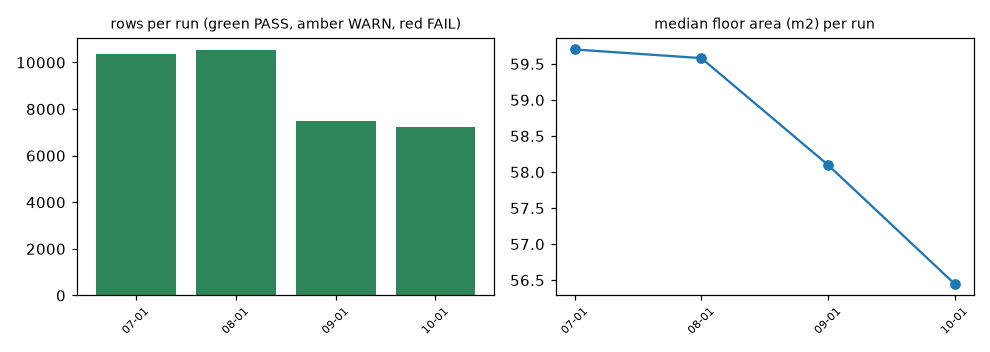

In [ ]:
from IPython.display import Image
Image("reports/dq_2026-10-01.png")

> **Aebon's Tip** — 이 스냅샷은 2026-10-28 에 내려받은 것이라, 6월 묶음에도 7월 이후에 들어온 취소일이 섞여 있습니다.
> `SELECT count(*) FROM trade_clean WHERE _run_id = '2026-07-01' AND 취소일 > '20260701'` 로 세어 보세요. 지나간 자료를 다시 흘려보낼(replay) 때는 그날 알 수 없었던 정보가 섞이지 않았는지 따로 살펴야 합니다.

## 8단계 · 깨진 묶음 넣기 — 규칙이 잡는가

이제 일부러 깨뜨린 묶음 넷을 만듭니다. 모두 9월 묶음에서 출발한 **연습용으로 고친 데이터**입니다.

| 도착일 | 깨뜨린 것 | 실제로 생기는 경우 |
|---|---|---|
| 10-02 | `건물면적(㎡)` 열을 뺐다 | 원천이 열 이름을 바꾸거나 내보내기 설정이 바뀜 |
| 10-03 | 금액을 만원 → **원**으로 바꿨다(×10,000) | 다른 API(원 단위)로 수집처를 바꿈 |
| 10-04 | 면적을 ㎡ → **평**으로 바꿨다(÷3.3058) | 사람이 엑셀에서 손으로 환산해 올림 |
| 10-05 | 6월 묶음을 그대로 다시 보냈다 | 수집 작업이 실패해 지난 파일이 다시 올라옴 |

In [ ]:
sept = pd.read_csv("landing/2026-10-01/trade.csv", dtype=str)

broken = {
    "2026-10-02": sept.drop(columns=["건물면적(㎡)"]),
    "2026-10-03": sept.assign(**{"물건금액(만원)": (pd.to_numeric(sept["물건금액(만원)"]) * 10000).astype(str)}),
    "2026-10-04": sept.assign(**{"건물면적(㎡)": (pd.to_numeric(sept["건물면적(㎡)"]) / 3.3058).round(2).astype(str)}),
    "2026-10-05": pd.read_csv("landing/2026-07-01/trade.csv", dtype=str),
}
con.close()
for day, df in broken.items():
    os.makedirs(f"landing/{day}", exist_ok=True)
    df.to_csv(f"landing/{day}/trade.csv", index=False)
    print(day, p7_dq.run_batch("dq.duckdb", f"landing/{day}/trade.csv", day))

2026-10-02 FAIL


2026-10-03 FAIL


2026-10-04 FAIL


2026-10-05 FAIL


어느 규칙이 잡았는지 봅니다.

In [ ]:
con = duckdb.connect("dq.duckdb")
caught = con.sql("""
    SELECT run_id, rule_id, status, failed, checked, note
    FROM dq_results
    WHERE run_id > '2026-10-01' AND status <> 'PASS'
    ORDER BY run_id, rule_id
""").df()
caught

,run_id,rule_id,status,failed,checked,note
0,2026-10-02,R01,FAIL,1,11,건물면적(㎡)
1,2026-10-02,R09,ERROR,<NA>,0,열 없음: 건물면적(㎡)
2,2026-10-02,R12,ERROR,<NA>,0,열 없음: 건물면적(㎡)
3,2026-10-02,R20,ERROR,<NA>,0,열 없음: 건물면적(㎡)
4,2026-10-03,R08,FAIL,7243,7243,
5,2026-10-03,R21,FAIL,1,1,"기준 60,500.0 → 545,000,000.0 (+900,726%)"
6,2026-10-04,R09,FAIL,101,7243,
7,2026-10-04,R20,FAIL,1,1,기준 58.8 → 17.1 (-71%)
8,2026-10-05,R19,FAIL,1,1,최근 계약일이 97일 전


> **확인 포인트** — 넷 모두 **FAIL** 이고, 잡은 규칙은 이렇습니다.
> 열 빠짐 → R01(필수 열) FAIL, 그 열을 쓰는 R09 · R12 · R20 은 실행하지 못해 ERROR.
> 원 단위 → R08(금액 범위) 7,243행 전부 + R21(중앙값 +900,726%).
> 평 단위 → R09(면적 5㎡ 미만) 101행 + R20(중앙값 -71%) — 범위만 봤다면 1.4%만 걸려 놓치기 쉬웠습니다.
> 다시 보낸 6월 묶음 → R19(최근 계약일이 97일 전)만 잡습니다. 다른 규칙으로는 멀쩡한 데이터입니다.

In [ ]:
hit = caught.groupby("run_id")["rule_id"].apply(list).to_dict()
assert hit == {"2026-10-02": ["R01", "R09", "R12", "R20"],
               "2026-10-03": ["R08", "R21"],
               "2026-10-04": ["R09", "R20"],
               "2026-10-05": ["R19"]}
assert caught.set_index(["run_id", "rule_id"]).loc[("2026-10-03", "R08"), "failed"] == 7243
assert caught.set_index(["run_id", "rule_id"]).loc[("2026-10-05", "R19"), "note"] == "최근 계약일이 97일 전"
assert con.sql("SELECT count(*) FROM dq_runs WHERE status = 'FAIL'").fetchall()[0][0] == 4

깨진 묶음은 적재되지 않았고(품질 관문), 깨진 묶음의 지표는 다음 날의 기준에 섞이지 않습니다(`baseline` 이 FAIL 실행을 뺍니다).

In [ ]:
print("적재된 행:", con.sql("SELECT count(*) FROM trade_clean").fetchall()[0][0])
print("다음 날 금액 기준:", p7_dq.baseline(con, "2026-10-06")["R21"])
assert con.sql("SELECT count(*) FROM trade_clean").fetchall()[0][0] == 35610
assert p7_dq.baseline(con, "2026-10-06")["R21"] == 60500

적재된 행: 35610
다음 날 금액 기준: 60500.0


> **자주 겪는 오류** — `baseline` 에서 `u.status <> 'FAIL'` 을 빼 보세요. 원 단위 묶음의 금액 중앙값(5억 4,500만 「만원」)이 기준에 섞여, 다음 날 정상 묶음이 오히려 「급락」으로 FAIL 이 됩니다.
> 규칙이 스스로 기준을 배우게 할 때는 **무엇으로 배우는지**를 꼭 정해 두세요.

마지막 리포트를 열어 봅니다.

In [ ]:
print(open("reports/dq_2026-10-03.md", encoding="utf-8").read().split("## 전체 규칙")[0])

# 실거래가 품질 리포트 — 2026-10-03

- 전체 판정: **FAIL**
- 원천: `landing/2026-10-03/trade.csv` · 7,243행
- 규칙 21개 — PASS 19 · WARN 0 · FAIL 2 · ERROR 0

## 통과하지 못한 규칙

| rule_id | descr | severity | checked | failed | fail_rate | status | note |
|---|---|---|---|---|---|---|---|
| R08 | 금액 500만~300억 원 | error | 7243 | 7243 | 1.0 | FAIL |  |
| R21 | 금액 중앙값이 지난 묶음들과 50% 넘게 다르지 않다 | error | 1 | 1 | 1.0 | FAIL | 기준 60,500.0 → 545,000,000.0 (+900,726%) |




## 9단계 · Airflow DAG — 매일 한 번

지금까지 손으로 부른 `run_batch` 를 Airflow 가 매일 부르게 합니다(8주차의 TaskFlow `@task`).
태스크는 둘입니다. 그날 착륙장에 파일이 왔는지 보고(없으면 건너뜀), 왔으면 검사합니다. 판정이 FAIL 이면 태스크를 실패시켜 알림이 가게 합니다.

In [ ]:
os.makedirs("dags", exist_ok=True)

In [ ]:
%%writefile dags/p7_dq_daily.py
import os
from datetime import datetime

from airflow.decorators import dag, task
from airflow.exceptions import AirflowFailException, AirflowSkipException

import p7_dq

LANDING = os.environ.get("P7_LANDING", "/opt/airflow/landing")
DB = os.environ.get("P7_DB", "/opt/airflow/dq/dq.duckdb")


@dag(dag_id="p7_dq_daily", schedule="@daily", start_date=datetime(2026, 7, 1), catchup=False,
     default_args={"retries": 1}, tags=["data-eng", "P7"])
def p7_dq_daily():

    @task
    def find_batch(ds=None):
        path = os.path.join(LANDING, ds, "trade.csv")
        if not os.path.exists(path):
            raise AirflowSkipException(f"{ds}: 들어온 묶음이 없습니다")
        return path

    @task
    def check_and_load(path, ds=None):
        status = p7_dq.run_batch(DB, path, ds)
        if status == "FAIL":
            raise AirflowFailException(f"{ds}: 품질 FAIL — reports/dq_{ds}.html 을 보세요")
        return status

    check_and_load(find_batch())


p7_dq_daily()

Writing dags/p7_dq_daily.py


이 노트북에는 Airflow 가 없으니 DAG 파일은 문법만 검사하고, 태스크가 할 일을 함수로 직접 불러 하루치를 돌려 봅니다.
Airflow 가 `ds`(실행 날짜)를 넘겨주듯 날짜를 넘깁니다.

In [ ]:
compile(open("dags/p7_dq_daily.py", encoding="utf-8").read(), "p7_dq_daily.py", "exec")
print("DAG 파일 문법 OK")

def one_day(ds, landing="landing", db="dq.duckdb"):
    """find_batch → check_and_load 를 Airflow 없이 차례로."""
    path = os.path.join(landing, ds, "trade.csv")
    if not os.path.exists(path):
        return "SKIP"
    return p7_dq.run_batch(db, path, ds)

con.close()
print({ds: one_day(ds) for ds in ["2026-09-30", "2026-10-01", "2026-10-03"]})

DAG 파일 문법 OK


{'2026-09-30': 'SKIP', '2026-10-01': 'PASS', '2026-10-03': 'FAIL'}


> **확인 포인트** — `{'2026-09-30': 'SKIP', '2026-10-01': 'PASS', '2026-10-03': 'FAIL'}` — 파일이 없는 날은 건너뛰고, 있는 날은 판정을 냅니다.

In [ ]:
assert {ds: one_day(ds) for ds in ["2026-09-30", "2026-10-01", "2026-10-03"]} == {"2026-09-30": "SKIP", "2026-10-01": "PASS", "2026-10-03": "FAIL"}

내 컴퓨터의 Airflow(8주차 Docker Compose)에서 돌리려면 이렇게 하세요.

```bash
# 1) dags/p7_dq_daily.py 와 p7_dq.py 를 Airflow 의 dags/ 폴더에 함께 둡니다(p7_dq 를 import 할 수 있게)
# 2) 이 노트북의 dq.duckdb(규칙 · 코드표가 든 파일)와 landing/ 을 컨테이너가 보는 폴더로 옮기고
#    P7_LANDING · P7_DB 환경 변수를 그 경로로 줍니다
# 3) 웹 UI 에서 p7_dq_daily 를 켜고, 날짜를 골라 한 번 돌립니다
airflow dags test p7_dq_daily 2026-10-03     # 컨테이너 안에서 — 그날 FAIL 로 끝나야 정상
```

> **자주 겪는 오류** — Airflow 의 여러 태스크가 같은 `dq.duckdb` 에 동시에 쓰면 `IO Error: Could not set lock on file` 이 납니다. DuckDB 파일은 쓰는 프로세스가 하나여야 합니다.
> 이 DAG 는 하루 한 번 · 태스크 하나만 쓰므로 괜찮지만, 여러 원천을 나란히 검사하려면 원천마다 파일을 나누거나 결과만 PostgreSQL 같은 서버 DB 에 쌓으세요.

## 10단계 · 더 해 보기

- 규칙 종류를 하나 더 만들어 보세요. 예: `pattern` — `계약일` 이 `^2026[0-9]{4}$` 에 맞는지(`regexp_matches`). `rule_sql` 에 `elif` 하나, 규칙 표에 한 줄이면 됩니다.
- R12 를 정확한 중복 검사로 바꾸려면 무엇이 더 있어야 할까요? 공개 자료에 없는 열(호수)이 무엇인지 적고, 「중복 의심」을 경고로 두는 지금 방식과 비교해 보세요.
- 리포트 HTML 을 메일로 보내려면 8주차 Airflow 의 `EmailOperator`(또는 슬랙 웹훅)를 `check_and_load` 뒤에 붙이세요. FAIL 일 때만 보내려면 `trigger_rule="one_failed"` 를 씁니다.
- P1 의 Iceberg 적재 앞에 이 관문을 두면, 깨진 묶음은 테이블에 스냅샷조차 남기지 않습니다. 「적재 후 검사 → 되돌리기」와 「검사 후 적재」 중 무엇이 나은지 이야기해 보세요.